In [ ]:
import pandas as pd

df = pd.read_csv("merged_dataset_clean.csv")
print(df.shape)
print(df['label'].value_counts())
df.head()

(1611, 2)
label
AI                     437
human                  334
Human                  332
ai                     192
Ai                      77
human                   31
AI-generated            20
ai                      11
HUMAN                   10
AI                      10
Humen                   10
Human                   10
AI_generated            10
human-written           10
hand written            10
ai generated            10
AI_generation           10
0                       10
ai generated            10
Ai generated            10
1                       10
collected                9
 humen                   9
collected                5
Human(collected)         5
Human(hand_written)      5
collect                  5
Human_written            5
Al                       1
humen                    1
 AI                      1
label                    1
Name: count, dtype: int64


,text,label
0,يُعدّ الذكاء الاصطناعي من أبرز الإنجازات التي ...,human
1,أصبح الذكاء الاصطناعي اليوم جزءاً محورياً من م...,human
2,تشير الدراسات والتقارير الحديثة المتخصصة إلى أ...,human
3,في رأيي الصريح والمتأمل، إن أخطر ما يواجهه مجت...,human
4,يُعتبر الذكاء الاصطناعي التوليدي من أحدث التطو...,human


In [ ]:
# تنظيف
df['label'] = df['label'].astype(str).str.strip().str.lower()

# حذف الصف الغلط
df = df[df['label'] != 'label']

# توحيد القيم
label_mapping = {

    # AI
    'ai': 'ai',
    'ai-generated': 'ai',
    'ai_generated': 'ai',
    'ai generated': 'ai',
    'ai generation': 'ai',
    'ai_generation': 'ai',
    'generated': 'ai',
    'al': 'ai',
    '1': 'ai',

    # Human
    'human': 'human',
    'humen': 'human',
    'human-written': 'human',
    'human_written': 'human',
    'human written': 'human',
    'hand written': 'human',
    'human(hand_written)': 'human',
    'human(collected)': 'human',
    'collected': 'human',
    'collect': 'human',
    '0': 'human'
}

df['label'] = df['label'].replace(label_mapping)

# التأكد النهائي
print(df['label'].unique())

['human' 'ai']


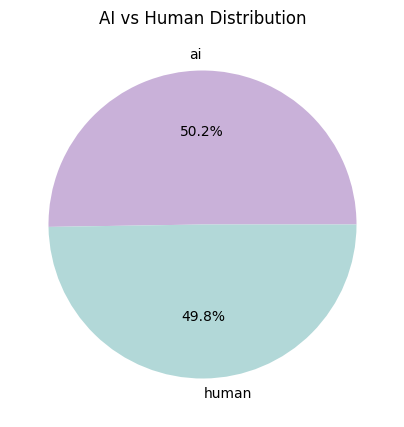

In [ ]:
import matplotlib.pyplot as plt

label_counts = df['label'].value_counts()

plt.figure(figsize=(5, 5))
plt.pie(label_counts.values,
        labels=label_counts.index,
        autopct='%1.1f%%',
        colors=['#C9B1D9', '#B2D8D8'])
plt.title('AI vs Human Distribution')
plt.show()

In [ ]:
print(df['label'].value_counts())

label
ai       809
human    801
Name: count, dtype: int64


In [ ]:
import re
import string
import nltk
from nltk.corpus import stopwords

In [ ]:
import nltk
nltk.download('stopwords')
arabic_stopwords = stopwords.words('arabic')

def normalize_text(text):
    text = re.sub(r'http\S+|www\S+', '', text)      # روابط
    text = re.sub(r'[a-zA-Z]', '', text)             # إنجليزي
    text = re.sub(r'\d+', '', text)                  # أرقام
    text = re.sub(r'[ًٌٍَُِّْ]', '', text)           # تشكيل
    text = re.sub(r'ـ', '', text)                    # تطويل
    text = re.sub('[إأآا]', 'ا', text)               # توحيد الألف
    text = re.sub(r'[^\w\s]', '', text)              # رموز
    text = re.sub(r'\s+', ' ', text).strip()         # مسافات
    tokens = text.split()
    tokens = [w for w in tokens if w not in arabic_stopwords]
    return ' '.join(tokens)


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [ ]:
# حذف الصفوف اللي فيها text فارغة
df = df.dropna(subset=['text'])

# تطبيق التنظيف على النصوص
df['clean_text'] = df['text'].astype(str).apply(normalize_text)
corpus = df['clean_text'].tolist()

# عرض النتيجة كداتا فريم
df[['text', 'clean_text', 'label']].head(10)

,text,clean_text,label
0,يُعدّ الذكاء الاصطناعي من أبرز الإنجازات التي ...,يعد الذكاء الاصطناعي ابرز الانجازات حققتها الب...,human
1,أصبح الذكاء الاصطناعي اليوم جزءاً محورياً من م...,اصبح الذكاء الاصطناعي اليوم جزءا محوريا مستقبل...,human
2,تشير الدراسات والتقارير الحديثة المتخصصة إلى أ...,تشير الدراسات والتقارير الحديثة المتخصصة الى ا...,human
3,في رأيي الصريح والمتأمل، إن أخطر ما يواجهه مجت...,رايي الصريح والمتامل ان اخطر يواجهه مجتمعنا ال...,human
4,يُعتبر الذكاء الاصطناعي التوليدي من أحدث التطو...,يعتبر الذكاء الاصطناعي التوليدي احدث التطورات ...,human
5,كشف تقرير صادر عن المنتدى الاقتصادي العالمي أن...,كشف تقرير صادر المنتدى الاقتصادي العالمي ان ال...,human
6,أعلنت كبرى شركات التقنية في العالم عن إطلاق جي...,اعلنت كبرى شركات التقنية العالم اطلاق جيل جديد...,human
7,رصد تقرير شامل صادر عن منظمة اليونسكو للتربية ...,رصد تقرير شامل صادر منظمة اليونسكو للتربية وال...,human
8,يشهد قطاع الرعاية الصحية ثورةً هادئة ولكن عميق...,يشهد قطاع الرعاية الصحية ثورة هادئة عميقة يقود...,human
9,تُشير الإحصاءات الصادرة عن مراكز أبحاث اقتصادي...,تشير الاحصاءات الصادرة مراكز ابحاث اقتصادية دو...,human


In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

bow = CountVectorizer()
X_bow = bow.fit_transform(corpus)

print("Shape:", X_bow.shape)
print("Vocab size:", len(bow.vocabulary_))
pd.DataFrame(X_bow.toarray(), columns=bow.get_feature_names_out()).head()

Shape: (1610, 24645)
Vocab size: 24645


,اؤمن,ائتمانية,اارياضه,ااصطناعي,اال,االخرى,االدراج,االسالم,االسباب,االستفادة,...,يومها,يومهم,يومي,يوميا,يومياته,يومياتهم,يومياشرب,يومية,يونامي,ييا
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer()
X_tfidf = tfidf.fit_transform(corpus)

print("Shape:", X_tfidf.shape)
print("Vocab size:", len(tfidf.vocabulary_))
pd.DataFrame(X_tfidf.toarray(), columns=tfidf.get_feature_names_out()).head()

Shape: (1610, 24645)
Vocab size: 24645


,اؤمن,ائتمانية,اارياضه,ااصطناعي,اال,االخرى,االدراج,االسالم,االسباب,االستفادة,...,يومها,يومهم,يومي,يوميا,يومياته,يومياتهم,يومياشرب,يومية,يونامي,ييا
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0625,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 80.2 MB/s eta 0:00:00


In [ ]:
!wget https://bakrianoo.ewr1.vultrobjects.com/aravec/full_grams_cbow_300_twitter.zip
!unzip -o full_grams_cbow_300_twitter.zip

--2026-06-02 10:46:02--  https://bakrianoo.ewr1.vultrobjects.com/aravec/full_grams_cbow_300_twitter.zip
Resolving bakrianoo.ewr1.vultrobjects.com (bakrianoo.ewr1.vultrobjects.com)... 108.61.0.122, 2001:19f0:0:22::100
Connecting to bakrianoo.ewr1.vultrobjects.com (bakrianoo.ewr1.vultrobjects.com)|108.61.0.122|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 3325529808 (3.1G) [application/zip]
Saving to: ‘full_grams_cbow_300_twitter.zip’

full_grams_cbow_300 100%[===================>]   3.10G  15.2MB/s    in 4m 49s  

2026-06-02 10:50:52 (11.0 MB/s) - ‘full_grams_cbow_300_twitter.zip’ saved [3325529808/3325529808]

Archive:  full_grams_cbow_300_twitter.zip
  inflating: full_grams_cbow_300_twitter.mdl  
  inflating: full_grams_cbow_300_twitter.mdl.trainables.syn1neg.npy  
  inflating: full_grams_cbow_300_twitter.mdl.wv.vectors.npy  


In [ ]:
import numpy as np
from gensim.models import Word2Vec

w2v_model = Word2Vec.load("full_grams_cbow_300_twitter.mdl")  # بعد ما تحمله

def aravec_sentence_vector(sentence):
    words = sentence.split()
    vectors = [w2v_model.wv[w] for w in words if w in w2v_model.wv]
    if len(vectors) == 0:
        return np.zeros(300)
    return np.mean(vectors, axis=0)

X_aravec = np.array([aravec_sentence_vector(s) for s in corpus])
print(X_aravec.shape)
pd.DataFrame(X_aravec).head()

(1610, 300)


,0,1,2,3,4,5,6,7,8,9,...,290,291,292,293,294,295,296,297,298,299
0,-0.292125,-0.190409,-0.059493,0.155779,0.446827,0.187521,0.789294,-0.317410,0.676184,0.163571,...,0.368161,-0.153108,-0.037972,0.429216,0.435127,-0.431758,-0.351655,0.407608,-0.245441,-0.350447
1,-0.237125,-0.582437,0.303441,0.093010,0.675267,0.321875,0.901353,-0.565993,0.502229,0.109159,...,0.254376,-0.090296,0.023038,0.626889,0.276497,-0.315940,-0.436800,0.315233,-0.234449,-0.377048
2,-0.185366,-0.287701,0.155214,0.038249,0.597850,0.262190,0.768006,-0.312915,0.554243,0.006218,...,0.086820,-0.085866,0.021140,0.605366,0.205162,-0.189766,-0.367279,0.490690,-0.387483,-0.283176
3,-0.033811,-0.101080,0.175459,0.196924,0.521860,0.302571,0.771242,-0.382864,0.267287,0.521440,...,0.262259,-0.345068,0.065464,0.413322,0.505205,-0.072366,-0.433617,0.401557,0.009380,-0.408866
4,-0.296173,-0.238448,0.108259,0.047554,0.293484,0.186593,0.787458,-0.509452,0.518630,0.038279,...,0.092717,0.027293,-0.091833,0.135482,-0.112842,-0.226847,-0.197813,0.198615,-0.420127,-0.143288


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 299.6/299.6 kB 22.7 MB/s eta 0:00:00


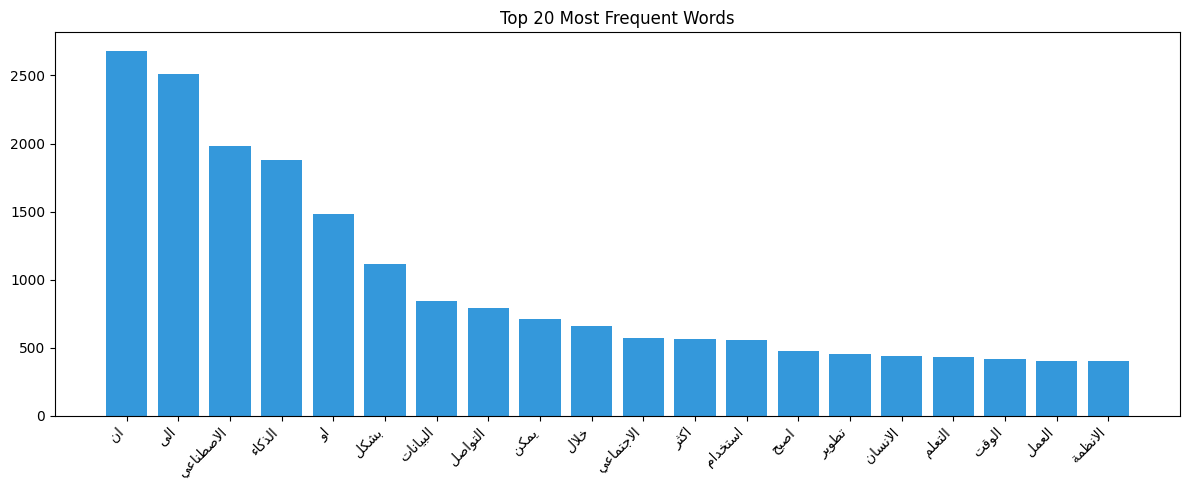

In [ ]:
from collections import Counter
!pip install arabic-reshaper python-bidi
import arabic_reshaper
from bidi.algorithm import get_display

all_words = ' '.join(corpus).split()
word_freq = Counter(all_words).most_common(20)

words, freqs = zip(*word_freq)

# تصحيح الكلمات العربية
words_fixed = [get_display(arabic_reshaper.reshape(w)) for w in words]

plt.figure(figsize=(12, 5))
plt.bar(words_fixed, freqs, color='#3498DB')
plt.title('Top 20 Most Frequent Words')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

y = df['label']

# TF-IDF
X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf, y, test_size=0.2, random_state=42)

# BoW
X_train_bow, X_test_bow, _, _ = train_test_split(
    X_bow, y, test_size=0.2, random_state=42)

# aravec
X_train_ft, X_test_ft, _, _ = train_test_split(
    X_aravec, y, test_size=0.2, random_state=42)



In [ ]:
from sklearn.naive_bayes import MultinomialNB, GaussianNB
from sklearn.metrics import accuracy_score, classification_report
model_nb_bow = MultinomialNB()
model_nb_bow.fit(X_train_bow, y_train)
y_pred = model_nb_bow.predict(X_test_bow)
print("Naive Bayes - BoW")
print(classification_report(y_test, y_pred))

model_nb_tfidf = MultinomialNB()
model_nb_tfidf.fit(X_train, y_train)
y_pred = model_nb_tfidf.predict(X_test)
print("Naive Bayes - TF-IDF")
print(classification_report(y_test, y_pred))

from sklearn.naive_bayes import GaussianNB

model_nb_ft = GaussianNB()
model_nb_ft.fit(X_train_ft, y_train)
print("Naive Bayes - fastText")
print(classification_report(y_test, model_nb_ft.predict(X_test_ft)))

Naive Bayes - BoW
              precision    recall  f1-score   support

          ai       0.80      0.96      0.87       164
       human       0.94      0.75      0.84       158

    accuracy                           0.86       322
   macro avg       0.87      0.86      0.86       322
weighted avg       0.87      0.86      0.86       322

Naive Bayes - TF-IDF
              precision    recall  f1-score   support

          ai       0.72      0.99      0.84       164
       human       0.99      0.61      0.75       158

    accuracy                           0.80       322
   macro avg       0.86      0.80      0.80       322
weighted avg       0.85      0.80      0.80       322

Naive Bayes - fastText
              precision    recall  f1-score   support

          ai       0.69      0.84      0.75       164
       human       0.78      0.60      0.68       158

    accuracy                           0.72       322
   macro avg       0.73      0.72      0.72       322
weighted avg

In [ ]:
from sklearn.svm import SVC
model_svm_bow = SVC(kernel='rbf')
model_svm_bow.fit(X_train_bow, y_train)
print("SVM - BoW")
print(classification_report(y_test, model_svm_bow.predict(X_test_bow)))

model_svm_tfidf = SVC(kernel='rbf')
model_svm_tfidf.fit(X_train, y_train)
print("SVM - TF-IDF")
print(classification_report(y_test, model_svm_tfidf.predict(X_test)))

model_svm_ft = SVC(kernel='rbf')
model_svm_ft.fit(X_train_ft, y_train)
print("SVM - fastText")
print(classification_report(y_test, model_svm_ft.predict(X_test_ft)))


SVM - BoW
              precision    recall  f1-score   support

          ai       0.88      0.83      0.86       164
       human       0.83      0.89      0.86       158

    accuracy                           0.86       322
   macro avg       0.86      0.86      0.86       322
weighted avg       0.86      0.86      0.86       322

SVM - TF-IDF
              precision    recall  f1-score   support

          ai       0.88      0.85      0.87       164
       human       0.85      0.88      0.87       158

    accuracy                           0.87       322
   macro avg       0.87      0.87      0.87       322
weighted avg       0.87      0.87      0.87       322

SVM - fastText
              precision    recall  f1-score   support

          ai       0.80      0.84      0.82       164
       human       0.83      0.78      0.81       158

    accuracy                           0.81       322
   macro avg       0.81      0.81      0.81       322
weighted avg       0.81      0.81   

In [ ]:
# Decision Tree
from sklearn.tree import DecisionTreeClassifier
model_dt_bow = DecisionTreeClassifier()
model_dt_bow.fit(X_train_bow, y_train)
print("Decision Tree - BoW")
print(classification_report(y_test, model_dt_bow.predict(X_test_bow)))

model_dt_tfidf = DecisionTreeClassifier()
model_dt_tfidf.fit(X_train, y_train)
print("Decision Tree - TF-IDF")
print(classification_report(y_test, model_dt_tfidf.predict(X_test)))

model_dt_ft = DecisionTreeClassifier()
model_dt_ft.fit(X_train_ft, y_train)
print("Decision Tree - AraVec")
print(classification_report(y_test, model_dt_ft.predict(X_test_ft)))

Decision Tree - BoW
              precision    recall  f1-score   support

          ai       0.69      0.68      0.69       164
       human       0.67      0.69      0.68       158

    accuracy                           0.68       322
   macro avg       0.68      0.68      0.68       322
weighted avg       0.68      0.68      0.68       322

Decision Tree - TF-IDF
              precision    recall  f1-score   support

          ai       0.73      0.71      0.72       164
       human       0.71      0.73      0.72       158

    accuracy                           0.72       322
   macro avg       0.72      0.72      0.72       322
weighted avg       0.72      0.72      0.72       322

Decision Tree - AraVec
              precision    recall  f1-score   support

          ai       0.71      0.61      0.66       164
       human       0.65      0.74      0.69       158

    accuracy                           0.67       322
   macro avg       0.68      0.68      0.67       322
weighted

In [ ]:
# Random Forest
from sklearn.ensemble import RandomForestClassifier
model_rf_bow = RandomForestClassifier()
model_rf_bow.fit(X_train_bow, y_train)
print("Random Forest - BoW")
print(classification_report(y_test, model_rf_bow.predict(X_test_bow)))

model_rf_tfidf = RandomForestClassifier()
model_rf_tfidf.fit(X_train, y_train)
print("Random Forest - TF-IDF")
print(classification_report(y_test, model_rf_tfidf.predict(X_test)))

model_rf_ft = RandomForestClassifier()
model_rf_ft.fit(X_train_ft, y_train)
print("Random Forest - AraVec")
print(classification_report(y_test, model_rf_ft.predict(X_test_ft)))

Random Forest - BoW
              precision    recall  f1-score   support

          ai       0.80      0.88      0.84       164
       human       0.86      0.77      0.81       158

    accuracy                           0.83       322
   macro avg       0.83      0.82      0.83       322
weighted avg       0.83      0.83      0.83       322

Random Forest - TF-IDF
              precision    recall  f1-score   support

          ai       0.84      0.87      0.85       164
       human       0.86      0.83      0.84       158

    accuracy                           0.85       322
   macro avg       0.85      0.85      0.85       322
weighted avg       0.85      0.85      0.85       322

Random Forest - AraVec
              precision    recall  f1-score   support

          ai       0.81      0.81      0.81       164
       human       0.80      0.80      0.80       158

    accuracy                           0.80       322
   macro avg       0.80      0.80      0.80       322
weighted

In [ ]:
# AdaBoost
from sklearn.ensemble import AdaBoostClassifier
model_ada_bow = AdaBoostClassifier()
model_ada_bow.fit(X_train_bow, y_train)
print("AdaBoost - BoW")
print(classification_report(y_test, model_ada_bow.predict(X_test_bow)))

model_ada_tfidf = AdaBoostClassifier()
model_ada_tfidf.fit(X_train, y_train)
print("AdaBoost - TF-IDF")
print(classification_report(y_test, model_ada_tfidf.predict(X_test)))

model_ada_ft = AdaBoostClassifier()
model_ada_ft.fit(X_train_ft, y_train)
print("AdaBoost - AraVec")
print(classification_report(y_test, model_ada_ft.predict(X_test_ft)))

AdaBoost - BoW
              precision    recall  f1-score   support

          ai       0.79      0.66      0.72       164
       human       0.70      0.82      0.76       158

    accuracy                           0.74       322
   macro avg       0.75      0.74      0.74       322
weighted avg       0.75      0.74      0.74       322

AdaBoost - TF-IDF
              precision    recall  f1-score   support

          ai       0.80      0.67      0.73       164
       human       0.71      0.83      0.76       158

    accuracy                           0.75       322
   macro avg       0.76      0.75      0.75       322
weighted avg       0.76      0.75      0.75       322

AdaBoost - AraVec
              precision    recall  f1-score   support

          ai       0.78      0.76      0.77       164
       human       0.76      0.77      0.76       158

    accuracy                           0.77       322
   macro avg       0.77      0.77      0.77       322
weighted avg       0.77

In [ ]:

X = X_tfidf.toarray()   # مهم جدًا لتحويل sparse → dense
y = df['label'].map({'human': 1, 'ai': 0})
X = X_tfidf.toarray()
y = df['label'].map({'human': 1, 'ai': 0})

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_encoded = le.fit_transform(df['label'])

X_train, X_test, y_train_enc, y_test_enc = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42)

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

model = Sequential([
    Dense(128, activation='relu', input_shape=(X.shape[1],)),
    Dropout(0.5),

    Dense(64, activation='relu'),
    Dropout(0.5),

    Dense(2, activation='softmax')
])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

In [ ]:
model.fit(X_train, y_train_enc,
          epochs=20,
          batch_size=32,
          validation_split=0.1,
          callbacks=[early])

Epoch 1/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 7s 96ms/step - accuracy: 0.6411 - loss: 0.6721 - val_accuracy: 0.7907 - val_loss: 0.6154
Epoch 2/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8568 - loss: 0.4761 - val_accuracy: 0.8140 - val_loss: 0.4215
Epoch 3/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9318 - loss: 0.2274 - val_accuracy: 0.8295 - val_loss: 0.3628
Epoch 4/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9569 - loss: 0.1190 - val_accuracy: 0.7984 - val_loss: 0.3988
Epoch 5/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9784 - loss: 0.0673 - val_accuracy: 0.8295 - val_loss: 0.3865
Epoch 6/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9853 - loss: 0.0414 - val_accuracy: 0.8450 - val_loss: 0.3995


11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
FNN - TF-IDF
Accuracy: 0.8633540372670807
              precision    recall  f1-score   support

          ai       0.88      0.84      0.86       164
       human       0.84      0.89      0.86       158

    accuracy                           0.86       322
   macro avg       0.86      0.86      0.86       322
weighted avg       0.86      0.86      0.86       322



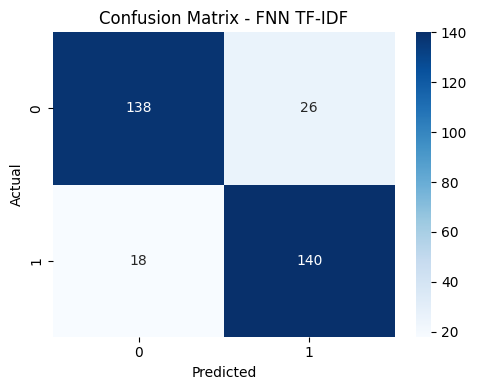

In [ ]:
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

y_pred_fnn = model.predict(X_test)
y_pred_fnn = y_pred_fnn.argmax(axis=1)

print("FNN - TF-IDF")
print("Accuracy:", accuracy_score(y_test_enc, y_pred_fnn))
print(classification_report(y_test_enc, y_pred_fnn, target_names=['ai', 'human']))

# 🔥 Confusion Matrix
cm = confusion_matrix(y_test_enc, y_pred_fnn)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title('Confusion Matrix - FNN TF-IDF')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.tight_layout()
plt.show()

In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer

tokenizer = Tokenizer(num_words=5000)

tokenizer.fit_on_texts(corpus)

sequences = tokenizer.texts_to_sequences(corpus)

print("Vocab size:", len(tokenizer.word_index))
print("Sample sequence:", sequences[0][:10])

Vocab size: 24829
Sample sequence: [84, 7, 6, 2, 266, 2740, 10, 105, 1, 795]


In [ ]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

X = pad_sequences(sequences, maxlen=100)

In [ ]:
vocab_size = len(tokenizer.word_index) + 1
embedding_matrix = np.zeros((vocab_size, 300))

for word, i in tokenizer.word_index.items():
    if word in w2v_model.wv:
        embedding_matrix[i] = w2v_model.wv[word]

print("Embedding matrix shape:", embedding_matrix.shape)

Embedding matrix shape: (24830, 300)


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_encoded = le.fit_transform(df['label'])

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42)

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.layers import Bidirectional


model = Sequential([
    Embedding(input_dim=vocab_size,
              output_dim=300,
              weights=[embedding_matrix],
              input_length=100,
              trainable=True),

    Bidirectional(LSTM(128)),

    Dropout(0.3),

    Dense(64, activation='relu'),

    Dense(2, activation='softmax')
])

In [ ]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

In [ ]:
history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    callbacks=[early]
)

Epoch 1/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 9s 34ms/step - accuracy: 0.6350 - loss: 0.6397 - val_accuracy: 0.7209 - val_loss: 0.5363
Epoch 2/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.7800 - loss: 0.4693 - val_accuracy: 0.7364 - val_loss: 0.5170
Epoch 3/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.8749 - loss: 0.3061 - val_accuracy: 0.8062 - val_loss: 0.4768
Epoch 4/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.9103 - loss: 0.2128 - val_accuracy: 0.7597 - val_loss: 0.5515
Epoch 5/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.9318 - loss: 0.1612 - val_accuracy: 0.8217 - val_loss: 0.5350
Epoch 6/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.9629 - loss: 0.0815 - val_accuracy: 0.7984 - val_loss: 0.6415


In [ ]:
y_pred_lstm = model.predict(X_test)
y_pred_lstm = y_pred_lstm.argmax(axis=1)

print("LSTM Results")
print("Accuracy:", accuracy_score(y_test, y_pred_lstm))
print(classification_report(y_test, y_pred_lstm, target_names=['ai', 'human']))

11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
LSTM Results
Accuracy: 0.8167701863354038
              precision    recall  f1-score   support

          ai       0.80      0.85      0.82       164
       human       0.83      0.78      0.81       158

    accuracy                           0.82       322
   macro avg       0.82      0.82      0.82       322
weighted avg       0.82      0.82      0.82       322



In [ ]:
!pip install transformers datasets accelerate -q

import pandas as pd
import numpy as np

from transformers import AutoTokenizer
from transformers import AutoModelForSequenceClassification
from transformers import Trainer, TrainingArguments

from datasets import Dataset

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

In [ ]:
# 1. تجهيز الداتا
texts = corpus
labels = df['label'].map({'ai': 0, 'human': 1}).tolist()
# 2. تقسيم الداتا
X_train, X_test, y_train, y_test = train_test_split(
    texts, labels, test_size=0.2, random_state=42)
# 3. تحويل لـ Dataset عشان يفهمه الBERT
train_dataset = Dataset.from_dict({'text': X_train, 'label': y_train})
test_dataset  = Dataset.from_dict({'text': X_test,  'label': y_test})

# 4. تحميل النموذج والـ Tokenizer
model_name = "aubmindlab/bert-base-arabertv2"
tokenizer  = AutoTokenizer.from_pretrained(model_name)
model      = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2)


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/384 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/611 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/720k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.31M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/543M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: aubmindlab/bert-base-arabertv2
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
bert.embeddings.position_ids               | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider

In [ ]:
# 5. Tokenize
def tokenize(batch):
    return tokenizer(batch['text'], padding=True, truncation=True, max_length=128)

train_dataset = train_dataset.map(tokenize, batched=True)
test_dataset  = test_dataset.map(tokenize, batched=True)


Map:   0%|          | 0/1288 [00:00<?, ? examples/s]

Map:   0%|          | 0/322 [00:00<?, ? examples/s]

In [ ]:
# 6. دالة التقييم
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    precision, recall, f1, _ = precision_recall_fscore_support(labels, predictions, average='weighted')
    accuracy = accuracy_score(labels, predictions)
    return {'accuracy': accuracy, 'precision': precision, 'recall': recall, 'f1': f1}


In [ ]:
training_args = TrainingArguments(
    output_dir='./results',
    eval_strategy='epoch',
    save_strategy='epoch',
    num_train_epochs=4,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    logging_dir='./logs',
    learning_rate=2e-5
)

`logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.


In [ ]:
# 8. Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    compute_metrics=compute_metrics
)


In [ ]:
# 9. تدريب وتقييم
trainer.train()
results = trainer.evaluate()
print(results)

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,No log,0.322052,0.863354,0.876028,0.863354,0.861913
2,No log,0.299965,0.878882,0.882930,0.878882,0.878423
3,No log,0.327302,0.885093,0.885399,0.885093,0.885032
4,0.373508,0.405103,0.878882,0.893130,0.878882,0.877524


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'eval_loss': 0.40510308742523193, 'eval_accuracy': 0.8788819875776398, 'eval_precision': 0.8931295795383436, 'eval_recall': 0.8788819875776398, 'eval_f1': 0.8775241968309414, 'eval_runtime': 2.3414, 'eval_samples_per_second': 137.523, 'eval_steps_per_second': 17.511, 'epoch': 4.0}


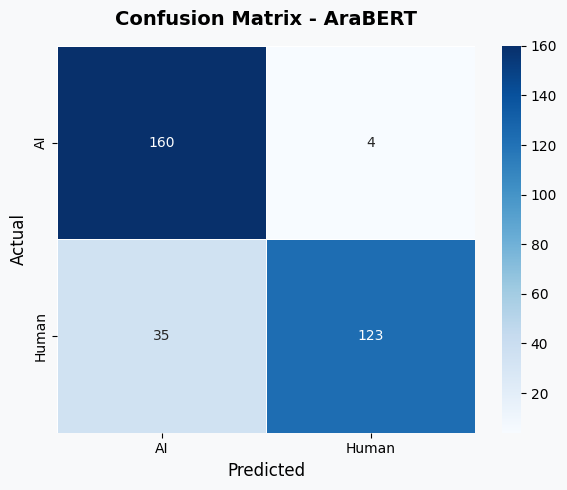

In [ ]:


# Confusion Matrix
from transformers import Trainer
import numpy as np
from sklearn.metrics import confusion_matrix
import seaborn as sns

predictions = trainer.predict(test_dataset)
y_pred = np.argmax(predictions.predictions, axis=-1)
y_true = predictions.label_ids

cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(6, 5), facecolor='#F8F9FA')
ax.set_facecolor('#F8F9FA')

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['AI', 'Human'],
            yticklabels=['AI', 'Human'],
            linewidths=0.5, ax=ax)

ax.set_xlabel('Predicted', fontsize=12)
ax.set_ylabel('Actual', fontsize=12)
ax.set_title('Confusion Matrix - AraBERT', fontsize=14, fontweight='bold', pad=15)

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

X_tfidf = tfidf.fit_transform(corpus)
y = df['label']

X_train_tfidf, X_test_tfidf, y_train, y_test = train_test_split(
    X_tfidf, y, test_size=0.2, random_state=42
)

In [ ]:
# GridSearch
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC

params = {
    'C': [0.1, 1, 10],
    'gamma': [1, 0.1, 0.01],
    'kernel': ['rbf']
}

grid = GridSearchCV(SVC(), params, refit=True, verbose=2, cv=3)
grid.fit(X_train_tfidf, y_train)
print(grid.best_params_)

Fitting 3 folds for each of 9 candidates, totalling 27 fits
[CV] END .........................C=0.1, gamma=1, kernel=rbf; total time=   2.0s
[CV] END .........................C=0.1, gamma=1, kernel=rbf; total time=   1.5s
[CV] END .........................C=0.1, gamma=1, kernel=rbf; total time=   1.6s
[CV] END .......................C=0.1, gamma=0.1, kernel=rbf; total time=   1.5s
[CV] END .......................C=0.1, gamma=0.1, kernel=rbf; total time=   1.5s
[CV] END .......................C=0.1, gamma=0.1, kernel=rbf; total time=   2.6s
[CV] END ......................C=0.1, gamma=0.01, kernel=rbf; total time=   1.2s
[CV] END ......................C=0.1, gamma=0.01, kernel=rbf; total time=   1.4s
[CV] END ......................C=0.1, gamma=0.01, kernel=rbf; total time=   1.3s
[CV] END ...........................C=1, gamma=1, kernel=rbf; total time=   1.1s
[CV] END ...........................C=1, gamma=1, kernel=rbf; total time=   1.2s
[CV] END ...........................C=1, gamma=1,

              precision    recall  f1-score   support

          ai       0.88      0.86      0.87       164
       human       0.86      0.87      0.87       158

    accuracy                           0.87       322
   macro avg       0.87      0.87      0.87       322
weighted avg       0.87      0.87      0.87       322



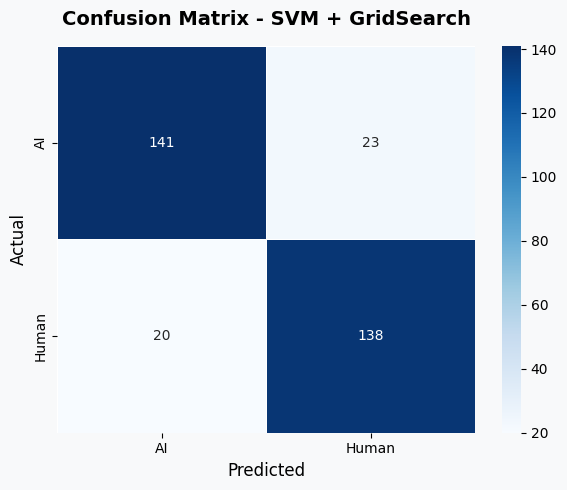

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

best_model = grid.best_estimator_
y_pred = best_model.predict(X_test_tfidf)

print(classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(6, 5), facecolor='#F8F9FA')
ax.set_facecolor('#F8F9FA')

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['AI', 'Human'],
            yticklabels=['AI', 'Human'],
            linewidths=0.5, ax=ax)

ax.set_xlabel('Predicted', fontsize=12)
ax.set_ylabel('Actual', fontsize=12)
ax.set_title('Confusion Matrix - SVM + GridSearch', fontsize=14, fontweight='bold', pad=15)

plt.tight_layout()
plt.show()

أدخل النص: الغذاء المتوازن مهم في حياتنا


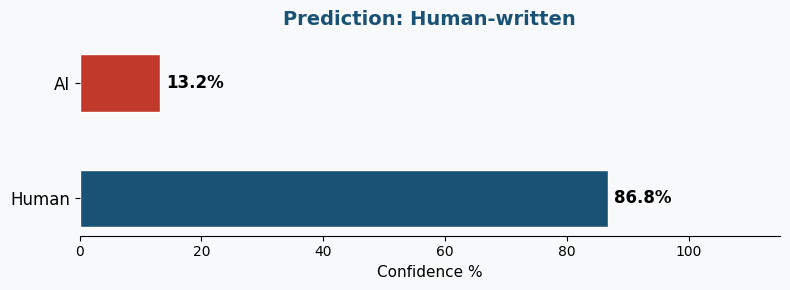

In [ ]:
# دربه مرة وحدة برا الدالة
model_svm_prob = SVC(kernel='rbf', probability=True)
model_svm_prob.fit(X_train_tfidf, y_train)

def predict_text(text):
    cleaned = normalize_text(text)
    vector = tfidf.transform([cleaned]).toarray()

    prediction = model_svm_prob.predict(vector)[0]
    proba = model_svm_prob.predict_proba(vector)[0]

    ai_prob    = proba[0] * 100
    human_prob = proba[1] * 100

    color = '#C0392B' if prediction == 'ai' else '#1A5276'

    fig, ax = plt.subplots(figsize=(8, 3), facecolor='#F8F9FA')
    ax.set_facecolor('#F8F9FA')

    bars = ax.barh(['Human', 'AI'], [human_prob, ai_prob],
                   color=['#1A5276', '#C0392B'], height=0.5, edgecolor='white')

    for bar, val in zip(bars, [human_prob, ai_prob]):
        ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2,
                f'{val:.1f}%', va='center', fontweight='bold', fontsize=12)

    ax.set_xlim(0, 115)
    ax.set_xlabel('Confidence %', fontsize=11)
    ax.set_title(f'Prediction: {"AI-generated" if prediction == "ai" else "Human-written"}',
                 fontsize=14, fontweight='bold', color=color, pad=15)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.tick_params(axis='y', labelsize=12)

    plt.tight_layout()
    plt.show()

text = input("أدخل النص: ")
predict_text(text)